# DATA LOADING

In [2]:
import pandas as pd

file_path = "/kaggle/input/datasets/muhammadnajibsalman/idx-80/IDX80 Metadata (1).xlsx"

# Read all sheets → returns dictionary {sheet_name: DataFrame}
sheets_dict = pd.read_excel(file_path, sheet_name=None)

# Access each dataset
for sheet_name, df in sheets_dict.items():
    print(f"Sheet: {sheet_name}")
    print(df.head())

# Example: store datasets separately
datasets = {}
for sheet_name, df in sheets_dict.items():
    datasets[sheet_name] = df

Sheet: Summary
   No Indeks Date Started                        Company_Name  \
0   1   AADI   2024-12-05                                 NaN   
1   2   ACES   2007-11-06     PT Aspirasi Hidup Indonesia Tbk   
2   3   ADMR   2022-01-03   PT Alamtri Minerals Indonesia Tbk   
3   4   ADRO   2008-07-16  PT Alamtri Resources Indonesia Tbk   
4   5   AKRA   2005-09-29               PT AKR Corporindo Tbk   

              Sector                        Industry      Market_Cap   Beta  \
0             Energy                    Thermal Coal  78842278445056    NaN   
1  Consumer Cyclical                Specialty Retail   6094859010048  0.190   
2    Basic Materials                     Coking Coal  72770553643008  0.418   
3             Energy                    Thermal Coal  70273206321152 -0.229   
4             Energy  Oil & Gas Refining & Marketing  27521678573568 -0.464   

     Country Currency Exchange  
0  Indonesia      IDR      JKT  
1  Indonesia      IDR      JKT  
2  Indonesia      ID

In [3]:
datasets["WIFI.JK"]

,Unnamed: 0,Price,Close,High,Low,Open,Volume
0,0,Ticker,WIFI.JK,WIFI.JK,WIFI.JK,WIFI.JK,WIFI.JK
1,1,Date,NaN,NaN,NaN,NaN,NaN
2,2,2020-12-30 00:00:00,655.205078,655.205078,655.205078,655.205078,1401100
3,3,2021-01-04 00:00:00,819.006409,819.006409,809.079058,814.042733,29516100
4,4,2021-01-05 00:00:00,833.8974,962.95295,814.0427,893.4615,25731300
...,...,...,...,...,...,...,...
1255,1255,2026-03-13 00:00:00,2040,2110,2010,2100,18230700
1256,1256,2026-03-16 00:00:00,1995,2070,1975,2040,17983500
1257,1257,2026-03-17 00:00:00,2000,2080,1990,2070,16197900
1258,1258,2026-03-25 00:00:00,2200,2230,2000,2000,38022200


In [4]:
import pandas as pd

def clean_sheet(df, sheet_name):
    # Drop useless first column (Unnamed: 0)
    df = df.drop(columns=df.columns[0])

    # Drop first two rows (Ticker + Date row)
    df = df.iloc[2:].reset_index(drop=True)

    # Rename columns
    df = df.rename(columns={
        'Price': 'date',
        'Close': 'close',
        'High': 'high',
        'Low': 'low',
        'Open': 'open',
        'Volume': 'volume'
    })

    # Convert types
    df['date'] = pd.to_datetime(df['date'])
    
    numeric_cols = ['close', 'high', 'low', 'open', 'volume']
    df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

    # Add stock identifier
    df['stock_id'] = sheet_name

    return df

In [5]:
xls = pd.ExcelFile(file_path)
all_data = []

for sheet in xls.sheet_names[1:]:
    df = pd.read_excel(xls, sheet_name=sheet)
    clean_df = clean_sheet(df, sheet)
    all_data.append(clean_df)

# Combine all stocks
combined_df = pd.concat(all_data, ignore_index=True)

print(combined_df.head())

        date        close          high          low         open     volume  \
0 2024-12-05  6241.059082   6241.059082  6241.059082  6241.059082     459400   
1 2024-12-06  7484.578125   7484.578125  7484.578125  7484.578125     446600   
2 2024-12-09  8962.723633   8962.723633  8962.723633  8962.723633   43658100   
3 2024-12-10  9643.139648  10675.495231  9009.648723  9854.303290  228636600   
4 2024-12-11  9009.649414   9807.378789  8986.186785  9643.140388  100219900   

  stock_id  
0  AADI.JK  
1  AADI.JK  
2  AADI.JK  
3  AADI.JK  
4  AADI.JK  


In [6]:
combined_df.shape, combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325319 entries, 0 to 325318
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   date      325319 non-null  datetime64[ns]
 1   close     325319 non-null  float64       
 2   high      325319 non-null  float64       
 3   low       325319 non-null  float64       
 4   open      325319 non-null  float64       
 5   volume    325319 non-null  int64         
 6   stock_id  325319 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 17.4+ MB


((325319, 7), None)

In [7]:
combined_df['stock_id'].value_counts()

stock_id
KPIG.JK    6466
MEDC.JK    6419
UNTR.JK    6353
INDF.JK    6335
ICBP.JK    6334
           ... 
MBMA.JK     692
AMMN.JK     646
BREN.JK     583
AADI.JK     304
RATU.JK     284
Name: count, Length: 80, dtype: int64

# DATA PREPROCESSING

In [8]:
combined_df.isna().sum()

date        0
close       0
high        0
low         0
open        0
volume      0
stock_id    0
dtype: int64

In [ ]:
import pandas as pd
import numpy as np

# Pivot
close = combined_df.pivot(index='date', columns='stock_id', values='close')
open_ = combined_df.pivot(index='date', columns='stock_id', values='open')
high = combined_df.pivot(index='date', columns='stock_id', values='high')
low = combined_df.pivot(index='date', columns='stock_id', values='low')
volume = combined_df.pivot(index='date', columns='stock_id', values='volume')

# Returns
returns = close.pct_change().dropna()

features = pd.DataFrame(index=returns.columns)

# --- A. Returns ---
features['mean_return'] = returns.mean()
features['median_return'] = returns.median()
features['cum_return'] = (1 + returns).prod() - 1
features['positive_ratio'] = (returns > 0).mean()

# --- B. Risk ---
features['volatility'] = returns.std()
features['downside_vol'] = returns[returns < 0].std()
features['skewness'] = returns.skew()
features['kurtosis'] = returns.kurtosis()

# Max drawdown
cum = (1 + returns).cumprod()
drawdown = cum / cum.cummax() - 1
features['max_drawdown'] = drawdown.min()

# VaR (5%)
features['VaR_5'] = returns.quantile(0.05)

# --- C. Momentum ---
features['trend'] = returns.apply(lambda x: np.polyfit(range(len(x)), x, 1)[0])
features['autocorr'] = returns.apply(lambda x: x.autocorr(lag=1))

features['rolling_mean_5'] = returns.rolling(5).mean().mean()
features['rolling_mean_20'] = returns.rolling(20).mean().mean()

features['momentum'] = close.iloc[-1] / close.mean() - 1

# --- D. OHLC ---
hl_spread = (high - low) / close
oc_return = (close - open_) / open_

features['avg_hl_spread'] = hl_spread.mean()
features['avg_oc_return'] = oc_return.mean()
features['range_volatility'] = hl_spread.std()

# --- E. Volume ---
features['mean_volume'] = volume.mean()
features['volume_volatility'] = volume.std()

features['vol_ret_corr'] = volume.corrwith(returns)

# --- F. Risk-adjusted ---
features['sharpe'] = features['mean_return'] / features['volatility']
features['sortino'] = features['mean_return'] / features['downside_vol']

# Clean
features = features.replace([np.inf, -np.inf], np.nan).dropna()

print(features.head())

In [ ]:
features_df = features.copy()
features_df.info()

# Time Series Clustering (1D CNN + Kmeans)

## Feature Extraction

In [23]:
import numpy as np
import pandas as pd

def create_sequences(df, seq_length=60):
    sequences = []
    stock_ids = []
    
    for stock_id, group in df.groupby('stock_id'):
        group = group.sort_values('date')
        
        # log returns
        group['log_return'] = np.log(group['close'] / group['close'].shift(1))
        returns = group['log_return'].dropna().values
        
        # create sequences
        for i in range(len(returns) - seq_length):
            seq = returns[i:i+seq_length]
            sequences.append(seq)
            stock_ids.append(stock_id)
    
    return np.array(sequences), np.array(stock_ids)

# Create sequences
X_seq, stock_ids = create_sequences(combined_df, seq_length=60)

X_seq.shape

(320439, 60)

In [24]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Normalize
scaler = StandardScaler()
X_seq = scaler.fit_transform(X_seq.reshape(-1, 1)).reshape(X_seq.shape)

In [66]:
import tensorflow as tf
from tensorflow.keras import layers, models

seq_length = X_seq.shape[1]

# Encoder
input_layer = layers.Input(shape=(seq_length, 1))

x = layers.Conv1D(64, 3, activation='relu', padding='same')(input_layer)
x = layers.MaxPooling1D(2)(x)

x = layers.Conv1D(32, 3, activation='relu', padding='same')(x)
x = layers.MaxPooling1D(2)(x)

x = layers.Flatten()(x)
latent = layers.Dense(64, name='latent')(x)

# Decoder
x = layers.Dense((seq_length // 4) * 16, activation='relu')(latent)
x = layers.Reshape((seq_length // 4, 16))(x)

x = layers.Conv1DTranspose(16, 3, activation='relu', padding='same')(x)
x = layers.UpSampling1D(2)(x)

x = layers.Conv1DTranspose(32, 3, activation='relu', padding='same')(x)
x = layers.UpSampling1D(2)(x)

output_layer = layers.Conv1D(1, 3, activation='linear', padding='same')(x)

autoencoder = models.Model(input_layer, output_layer)
autoencoder.compile(optimizer='AdamW', loss='mse')

autoencoder.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 60, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_17 (Conv1D)              │ (None, 60, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_12 (MaxPooling1D) │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_18 (Conv1D)              │ (None, 30, 32)         │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_13 (MaxPooling1D) │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │        30,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 240)            │        15,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_6 (Reshape)             │ (None, 15, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_10             │ (None, 15, 16)         │           784 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_10 (UpSampling1D) │ (None, 30, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_11             │ (None, 30, 32)         │         1,568 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_11 (UpSampling1D) │ (None, 60, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_19 (Conv1D)              │ (None, 60, 1)          │            97 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,265 (215.88 KB)

 Trainable params: 55,265 (215.88 KB)

 Non-trainable params: 0 (0.00 B)

In [67]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',     
    patience=5,             
    restore_best_weights=True
)

history = autoencoder.fit(
    X_seq, X_seq,
    epochs=50,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping]
)

Epoch 1/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - loss: 0.7218 - val_loss: 0.5820
Epoch 2/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.4761 - val_loss: 0.3004
Epoch 3/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.1942 - val_loss: 0.1184
Epoch 4/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.1130 - val_loss: 0.0617
Epoch 5/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0885 - val_loss: 0.0488
Epoch 6/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.0681 - val_loss: 0.0368
Epoch 7/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.0542 - val_loss: 0.0417
Epoch 8/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0483 - val_loss: 0.0413
Epoch 9/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0595 - val_loss: 0.0461
Epoch 10/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0511 - val_loss: 0.0851
Epoch 11/50
2254/2254 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0604 - val_loss: 0.0344
Epoch 12/50
2254/2254 ━━━━━━━

In [68]:
encoder = models.Model(
    inputs=autoencoder.input,
    outputs=autoencoder.get_layer('latent').output
)

latent_features = encoder.predict(X_seq)

10014/10014 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step


In [69]:
latent_df = pd.DataFrame(latent_features)
latent_df['stock_id'] = stock_ids

# Average embedding per stock
stock_embeddings = latent_df.groupby('stock_id').mean()

In [75]:
encoder.save("encoder_model.keras")

## Cluster using K-Means

In [70]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

latent_scaled = StandardScaler().fit_transform(stock_embeddings)

kmeans = KMeans(n_clusters=3, random_state=42, init='k-means++')
labels = kmeans.fit_predict(latent_scaled)

features_df['ts_kmeans_cluster'] = labels

In [71]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Assuming you already did clustering
labels = features_df['ts_kmeans_cluster']

# --- Metrics ---
sil_score = silhouette_score(latent_scaled, labels)
db_index = davies_bouldin_score(latent_scaled, labels)
ch_score = calinski_harabasz_score(latent_scaled, labels)

print("Silhouette Score:", sil_score)
print("Davies-Bouldin Index:", db_index)
print("Calinski-Harabasz Score:", ch_score)

Silhouette Score: 0.4690191
Davies-Bouldin Index: 0.8292398617029731
Calinski-Harabasz Score: 80.91343


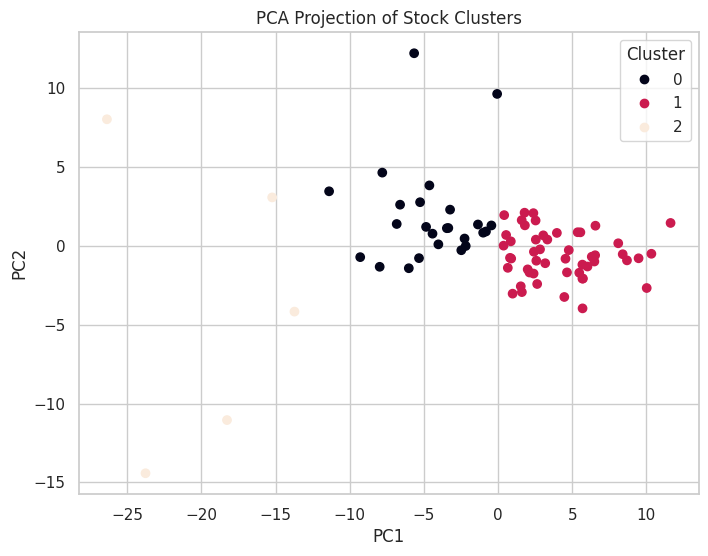

In [72]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Apply PCA (2 components)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(latent_scaled)

# Plot
plt.figure(figsize=(8,6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=features_df['ts_kmeans_cluster'],
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Projection of Stock Clusters')

# Legend
plt.legend(*scatter.legend_elements(), title="Cluster")

plt.grid(True)
plt.show()

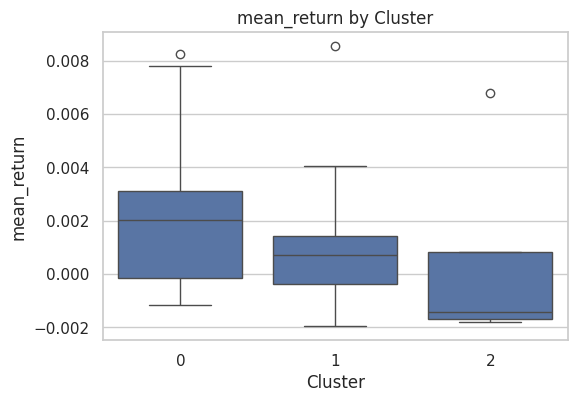

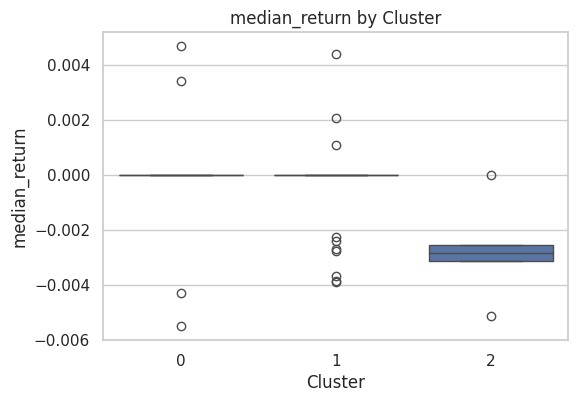

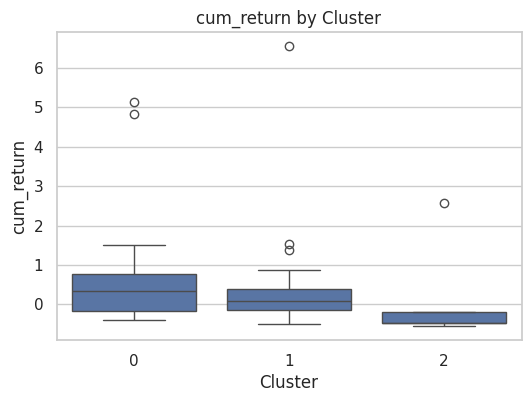

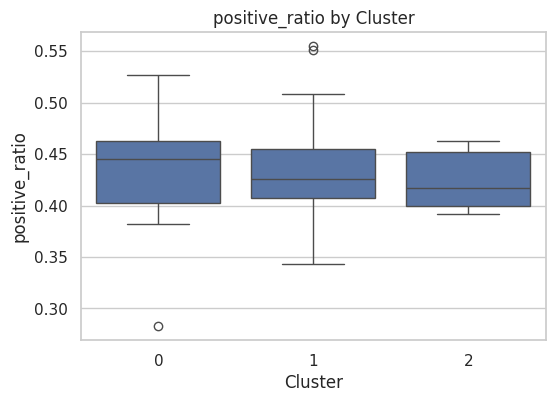

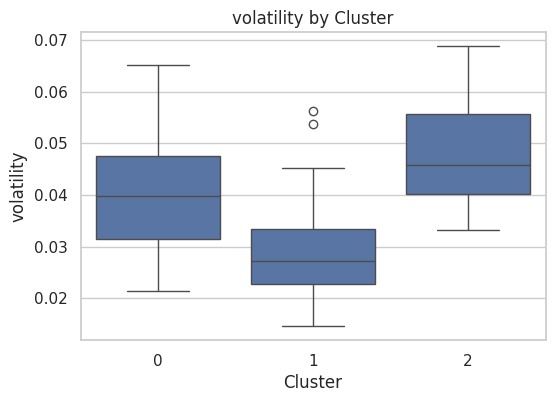

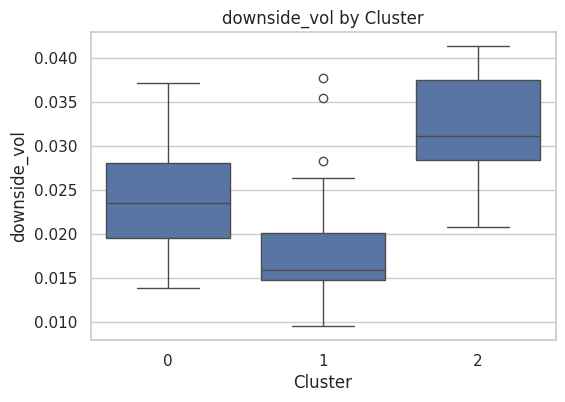

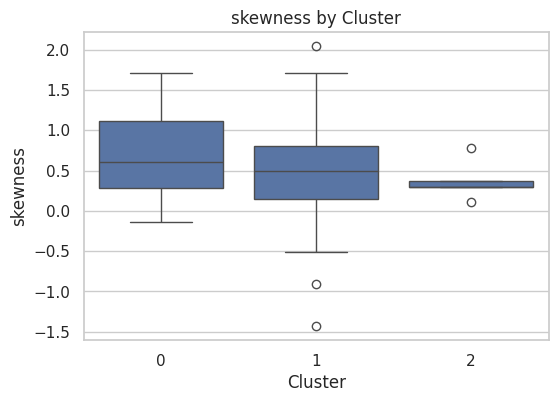

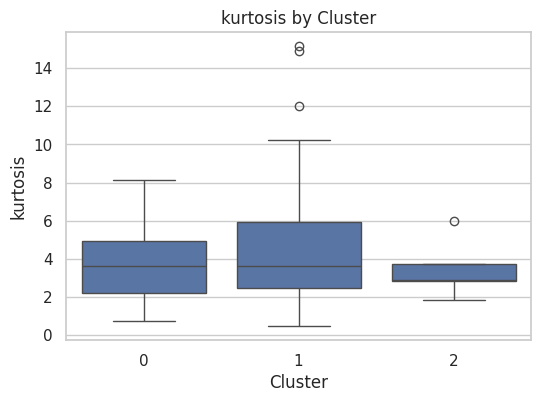

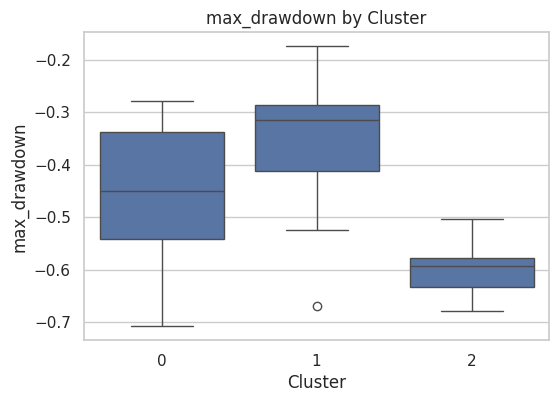

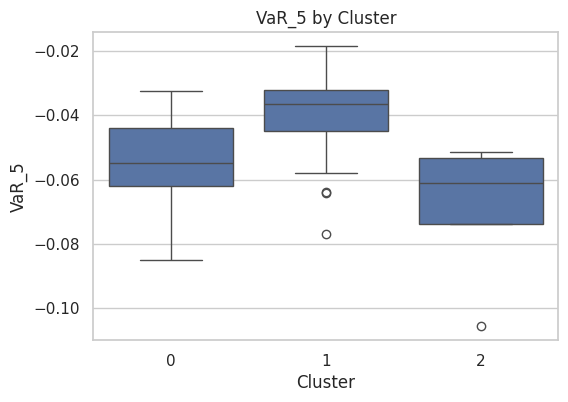

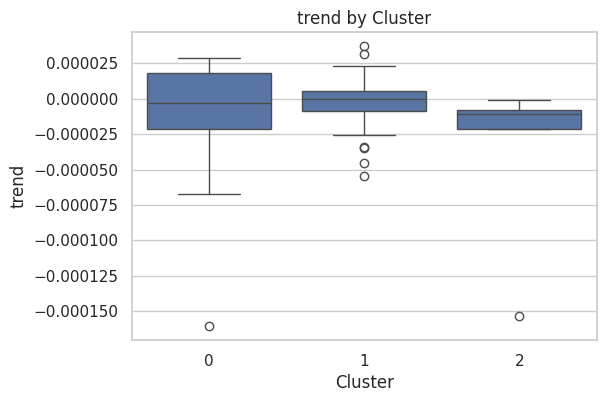

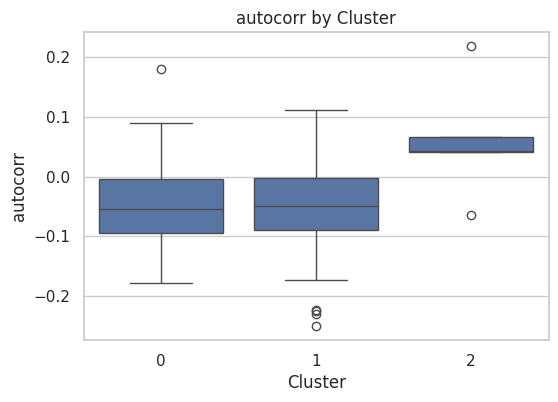

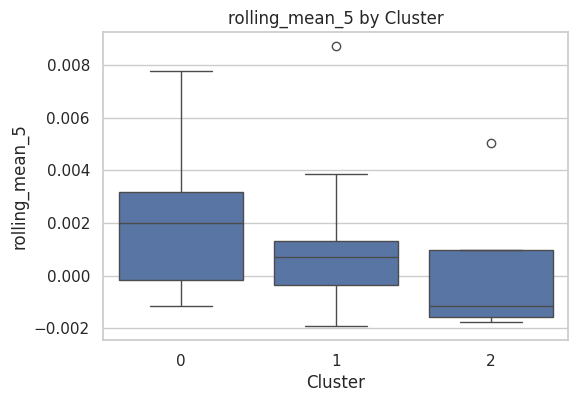

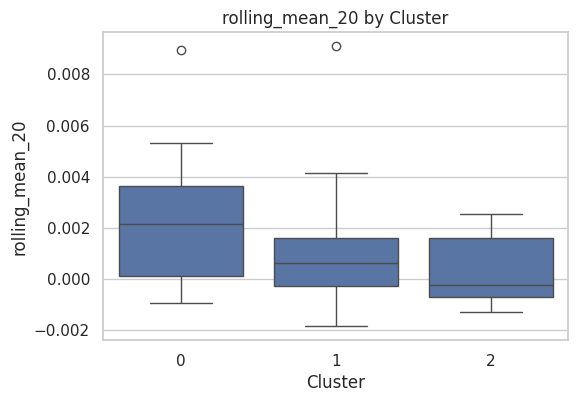

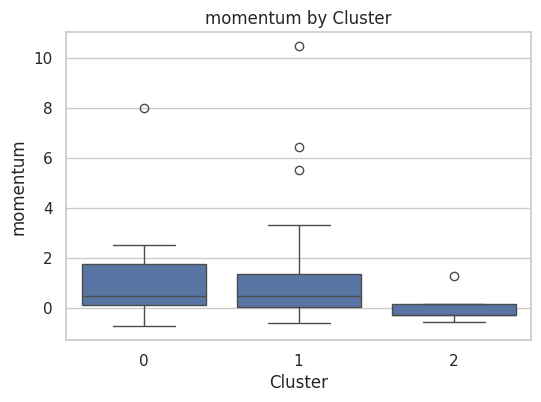

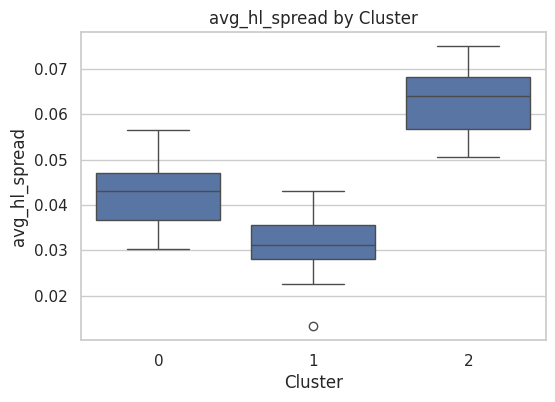

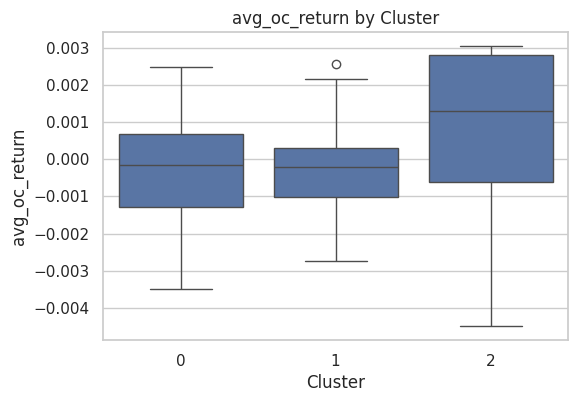

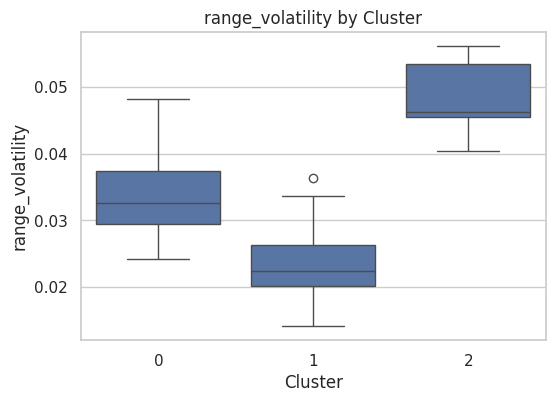

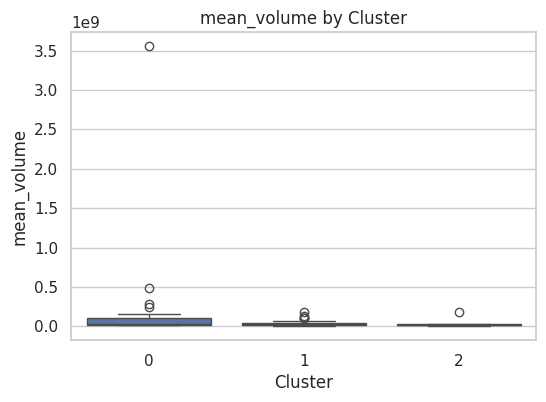

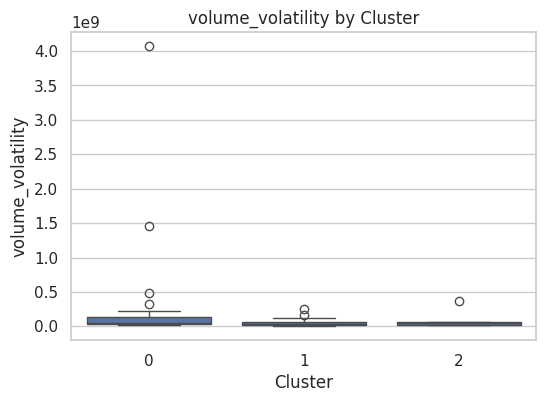

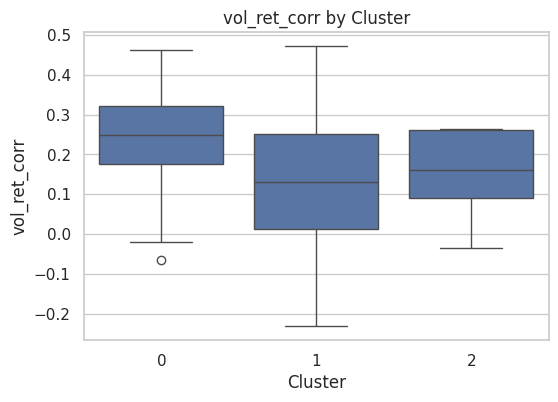

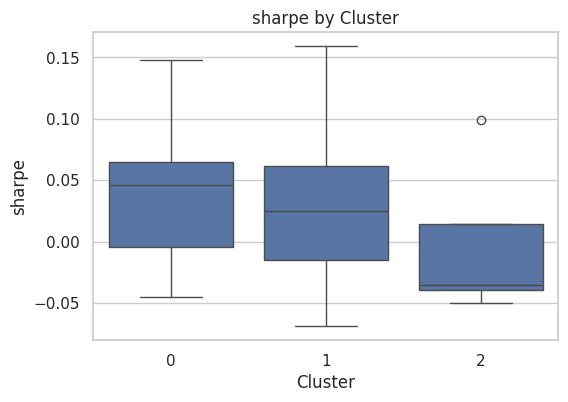

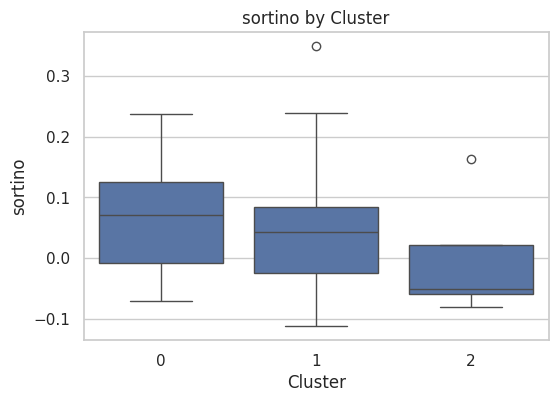

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

for col in feature_cols:
    plt.figure(figsize=(6,4))
    
    sns.boxplot(
        x='ts_kmeans_cluster',
        y=col,
        data=features_df
    )
    
    plt.title(f'{col} by Cluster')
    plt.xlabel('Cluster')
    plt.ylabel(col)
    plt.show()

In [78]:
features_df.index

Index(['AADI.JK', 'ACES.JK', 'ADMR.JK', 'ADRO.JK', 'AKRA.JK', 'AMMN.JK',
       'AMRT.JK', 'ANTM.JK', 'ARTO.JK', 'ASII.JK', 'BBCA.JK', 'BBNI.JK',
       'BBRI.JK', 'BBTN.JK', 'BMRI.JK', 'BREN.JK', 'BRMS.JK', 'BRPT.JK',
       'BSDE.JK', 'BTPS.JK', 'BUKA.JK', 'BUMI.JK', 'CMRY.JK', 'CPIN.JK',
       'CTRA.JK', 'CUAN.JK', 'DSNG.JK', 'DSSA.JK', 'ELSA.JK', 'EMTK.JK',
       'ENRG.JK', 'ERAA.JK', 'ESSA.JK', 'EXCL.JK', 'GOTO.JK', 'HEAL.JK',
       'HRTA.JK', 'HRUM.JK', 'ICBP.JK', 'INCO.JK', 'INDF.JK', 'INDY.JK',
       'INKP.JK', 'INTP.JK', 'ISAT.JK', 'ITMG.JK', 'JPFA.JK', 'JSMR.JK',
       'KIJA.JK', 'KLBF.JK', 'KPIG.JK', 'MAPA.JK', 'MAPI.JK', 'MBMA.JK',
       'MDKA.JK', 'MEDC.JK', 'MIKA.JK', 'MTEL.JK', 'MYOR.JK', 'NCKL.JK',
       'PANI.JK', 'PGAS.JK', 'PGEO.JK', 'PNLF.JK', 'PTBA.JK', 'PTRO.JK',
       'PWON.JK', 'RAJA.JK', 'RATU.JK', 'SCMA.JK', 'SIDO.JK', 'SMGR.JK',
       'SMRA.JK', 'SSIA.JK', 'TAPG.JK', 'TLKM.JK', 'TOWR.JK', 'UNTR.JK',
       'UNVR.JK', 'WIFI.JK'],
      dtype='object',

In [82]:
combined_df['date'].max()

Timestamp('2026-03-26 00:00:00')

In [84]:
combined_df.to_csv("combined_df.csv")

# Deployment Things

In [77]:
import numpy as np
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist


def align_clusters(old_centroids, new_centroids):
    
    # Compute distance matrix
    distance_matrix = cdist(old_centroids, new_centroids)

    # Hungarian algorithm
    old_idx, new_idx = linear_sum_assignment(distance_matrix)

    # Create mapping
    mapping = {
        new_cluster: old_cluster
        for old_cluster, new_cluster in zip(old_idx, new_idx)
    }

    return mapping

In [ ]:
mapping = align_clusters(old_centers, new_centers)

aligned_labels = np.vectorize(mapping.get)(new_labels)